# 01. 서울 아파트 거래가격과 거래량의 시기·지역별 변화

**질문:** 서울 아파트의 거래가격과 거래량은 시기·지역별로 어떻게 달라졌는가?

**방법과 지표**
- 월별 ㎡당 중위가격(만원/㎡), 총액 중위가격(억원, 보조), 거래량(건).
- **구성 보정 지수:** log(㎡당 가격) ~ 월 더미 + 구 고정효과 + 면적·연식·층 구간 더미(월 더미 시간 지수, 단지 클러스터 표준오차). 기준월 2017-11=100. 검증용으로 단지 고정효과 지수(같은 단지 안의 가격 변화만 쓰는 반복매매형 지수)를 함께 만든다.
- 일괄 거래(같은 단지·같은 날 10건 이상, 00 노트북 기준)를 **포함한 결과와 뺀 결과를 나란히** 둔다.
- 거래 구성 변화: 구 가격 3분위(2018년 구별 ㎡당 중위가격 기준)·면적 구간 비중의 분기별 누적막대, 전년 동월 대비 평균 log 가격 변화의 구성 분해(구×면적 칸 기준 within/구성 변화 몫).
- 구×분기 ㎡당 중위가격 히트맵, 구별 구성 보정 지수.
- STL 분해(주기 12개월, robust)로 추세·계절·잔차를 나눈다.

**사용한 교재 장:** 6장 EDA(분포·박스플롯), 5장 다중회귀(구성 보정 지수).
**교재에서 바꾼 점과 이유:** 교재 5장 회귀는 예측용이지만 여기서는 월 더미 계수를 "같은 구성의 집값" 지수로 읽는 데 쓴다. 단순 중위가격은 거래되는 지역·면적이 달마다 달라 시장 방향과 다르게 움직일 수 있기 때문이다(조율안 01). 교재 6장의 IQR 삭제는 쓰지 않고 00의 플래그로 포함·제외본을 나눈다. 시계열끼리의 상관 히트맵은 추세 때문에 허위 상관이 생기므로 그리지 않는다.

**표본:** `transactions.parquet`의 `in_base`(취소·완전 중복·부분 월 제외) 2017-11~2026-09. 2026-08~09는 잠정 월, 2026-10은 부분 월로 거래량에만 따로 표시한다.

In [1]:
import os
import sys
from pathlib import Path


def _find_root():
    env = os.environ.get("REANALYSIS_ROOT")
    if env:
        return Path(env).resolve()
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "AGENTS.md").exists():
            return p
    raise FileNotFoundError("AGENTS.md가 있는 프로젝트 루트를 찾지 못했습니다")


ROOT = _find_root()
sys.path.insert(0, str(ROOT / "src" / "재검증"))
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import reanalysis_utils as ru

SEED = ru.SEED
DATA = ROOT / "data"
plt = ru.set_korean_font()

In [2]:
OUT = ru.out_dir(ROOT, "01")
tx = ru.load_tx(ROOT)
MONTHS = ru.ym_range("2017-11", "2026-09")
valid = tx[~tx["is_cancelled"] & ~tx["is_dup_exact"] & ~tx["dong_key_missing"]]
base = tx[tx["in_base"]].reset_index(drop=True)
nob = tx[tx["in_base_nobulk"]].reset_index(drop=True)
pd.Series({"valid_incl_partial": len(valid), "in_base": len(base), "in_base_nobulk": len(nob),
           "n_complex": base["complex_id"].nunique()}).to_frame("rows")

,rows
valid_incl_partial,525949
in_base,523320
in_base_nobulk,519370
n_complex,8908


## 1. 월별 중위가격과 거래량(일괄 거래 포함·제외)

In [3]:
def monthly(d, tag):
    g = d.groupby("contract_ym")
    return pd.DataFrame({"n": g.size(), "median_ppa": g["ppa_manwon"].median(),
                         "median_price_eok": g["price_eok"].median()}).add_suffix("_" + tag)


mon = pd.concat([monthly(valid, "all"), monthly(valid[~valid["is_bulk"]], "nobulk")], axis=1).reset_index()
mon = mon.rename(columns={"contract_ym": "month"})
mon["bulk_n"] = mon["n_all"] - mon["n_nobulk"]
mon["is_partial"] = mon["month"].isin(["2017-10", "2026-10"])
mon["is_provisional"] = mon["month"].isin(["2026-08", "2026-09"])
mon.tail(6)

,month,n_all,median_ppa_all,median_price_eok_all,n_nobulk,median_ppa_nobulk,median_price_eok_nobulk,bulk_n,is_partial,is_provisional
103,2026-05,8733,1375.358166,10.10,8611,1377.777778,10.2800,122,False,False
104,2026-06,5317,1308.557969,9.60,5299,1313.309776,9.6000,18,False,False
105,2026-07,5689,1354.472527,9.35,5479,1341.687552,9.6200,210,False,False
106,2026-08,3587,1278.305332,8.70,3536,1271.655883,8.8350,51,False,True
107,2026-09,3209,1314.902225,8.80,3089,1305.991856,9.0000,120,False,True
108,2026-10,1531,1285.915210,8.40,1452,1275.256704,8.7875,79,True,False


`n_all`은 일괄 거래 포함, `n_nobulk`는 제외 거래량이다. 2026-10은 26일까지만 있는 부분 월이고 신고 기한(계약 후 30일)이 남아 있어 거래량이 작게 나온다.

## 2. 구성 보정 지수

In [4]:
idx_all, res_all = ru.time_dummy_index(base, MONTHS, fe="gu", char_refs=ru.CHAR_REFS, cluster="complex_id")
idx_nob, res_nob = ru.time_dummy_index(nob, MONTHS, fe="gu", char_refs=ru.CHAR_REFS, cluster="complex_id")
idx_cx, _ = ru.time_dummy_index(nob, MONTHS, fe="complex_id", char_refs=ru.CHAR_REFS_NOAGE, with_se=False)
pd.DataFrame({"spec": ["구FE+특성(포함)", "구FE+특성(제외)", "단지FE+면적·층(제외)"],
              "n": [res_all["n"], res_nob["n"], _["n"]],
              "clusters": [res_all["n_clusters"], res_nob["n_clusters"], np.nan],
              "r2_within": [res_all["r2_within"], res_nob["r2_within"], _["r2_within"]]})

,spec,n,clusters,r2_within
0,구FE+특성(포함),523320,8908.0,0.484617
1,구FE+특성(제외),519370,8818.0,0.485825
2,단지FE+면적·층(제외),519370,NaN,0.824760


In [5]:
def change(idx, res, m0, m1):
    """두 달 사이 지수 변화율(%)과 95% 신뢰구간(월 계수 공분산 사용)."""
    b0 = 0.0 if m0 == MONTHS[0] else res["beta"][f"m={m0}"]
    b1 = res["beta"][f"m={m1}"]
    V = res["vcov"]
    v = V.loc[f"m={m1}", f"m={m1}"]
    if m0 != MONTHS[0]:
        v = v + V.loc[f"m={m0}", f"m={m0}"] - 2 * V.loc[f"m={m0}", f"m={m1}"]
    se = np.sqrt(v)
    d = b1 - b0
    return {"pct": (np.exp(d) - 1) * 100, "lo": (np.exp(d - 1.96 * se) - 1) * 100,
            "hi": (np.exp(d + 1.96 * se) - 1) * 100}


def med_change_boot(d, m0, m1, B=999, seed=SEED):
    a = d.loc[d["contract_ym"] == m0, "ppa_manwon"].to_numpy()
    b = d.loc[d["contract_ym"] == m1, "ppa_manwon"].to_numpy()
    rng = np.random.default_rng(seed)
    pt = (np.median(b) / np.median(a) - 1) * 100
    bs = [(np.median(rng.choice(b, b.size)) / np.median(rng.choice(a, a.size)) - 1) * 100 for _ in range(B)]
    return {"pct": pt, "lo": np.percentile(bs, 2.5), "hi": np.percentile(bs, 97.5)}


comp_rows = []
for (m0, m1, lab) in [("2025-09", "2026-09", "전년 동월 대비(2026-09)"), ("2026-08", "2026-09", "전월 대비(2026-09)"),
                      ("2017-11", "2026-09", "누적(2017-11→2026-09)")]:
    for nm, fn in [("중위 ㎡당(포함)", lambda: med_change_boot(base, m0, m1)),
                   ("중위 ㎡당(제외)", lambda: med_change_boot(nob, m0, m1)),
                   ("보정 지수(포함)", lambda: change(idx_all, res_all, m0, m1)),
                   ("보정 지수(제외)", lambda: change(idx_nob, res_nob, m0, m1))]:
        r = fn()
        comp_rows.append({"comparison": lab, "m0": m0, "m1": m1, "measure": nm, **r})
comp = pd.DataFrame(comp_rows)
comp.pivot_table(index="measure", columns="comparison", values="pct").round(2)

comparison,누적(2017-11→2026-09),전년 동월 대비(2026-09),전월 대비(2026-09)
measure,,,
보정 지수(제외),104.42,3.06,1.48
보정 지수(포함),103.32,2.55,1.28
중위 ㎡당(제외),75.11,-10.33,2.70
중위 ㎡당(포함),76.30,-9.58,2.86


위 표는 같은 두 달을 네 가지 지표로 비교한 변화율(%)이다. 중위가격의 신뢰구간은 월 안 거래를 999회 재표본한 부트스트랩, 지수의 신뢰구간은 단지 클러스터 표준오차로 구했다(아래 셀에 하한·상한).

In [6]:
comp.round(2)

,comparison,m0,m1,measure,pct,lo,hi
0,전년 동월 대비(2026-09),2025-09,2026-09,중위 ㎡당(포함),-9.58,-11.24,-7.16
1,전년 동월 대비(2026-09),2025-09,2026-09,중위 ㎡당(제외),-10.33,-11.94,-8.17
2,전년 동월 대비(2026-09),2025-09,2026-09,보정 지수(포함),2.55,0.61,4.53
3,전년 동월 대비(2026-09),2025-09,2026-09,보정 지수(제외),3.06,1.20,4.96
4,전월 대비(2026-09),2026-08,2026-09,중위 ㎡당(포함),2.86,0.49,5.89
5,전월 대비(2026-09),2026-08,2026-09,중위 ㎡당(제외),2.70,0.02,5.54
6,전월 대비(2026-09),2026-08,2026-09,보정 지수(포함),1.28,-0.79,3.39
7,전월 대비(2026-09),2026-08,2026-09,보정 지수(제외),1.48,-0.32,3.31
8,누적(2017-11→2026-09),2017-11,2026-09,중위 ㎡당(포함),76.30,72.51,81.59
9,누적(2017-11→2026-09),2017-11,2026-09,중위 ㎡당(제외),75.11,71.26,79.79


In [7]:
ix = pd.DataFrame({"month": MONTHS})
for nm, d in [("index_all", idx_all), ("index_nobulk", idx_nob), ("index_complexfe", idx_cx)]:
    ix = ix.merge(d[["month", "index"]].rename(columns={"index": nm}), on="month")
for nm, d in [("se_all", idx_all), ("se_nobulk", idx_nob)]:
    ix = ix.merge(d[["month", "se"]].rename(columns={"se": nm}), on="month")
ix = ix.merge(mon[["month", "median_ppa_all", "median_ppa_nobulk", "n_all", "n_nobulk"]], on="month", how="left")
for c in ["median_ppa_all", "median_ppa_nobulk"]:
    ix[c + "_rel"] = ix[c] / ix[c].iloc[0] * 100
ix["is_provisional"] = ix["month"].isin(["2026-08", "2026-09"])
sub = ix[ix["month"] <= "2023-12"]
peak_m = sub.loc[sub["index_nobulk"].idxmax(), "month"]
after = ix[(ix["month"] > peak_m) & (ix["month"] <= "2024-12")]
trough_m = after.loc[after["index_nobulk"].idxmin(), "month"]
phase = pd.DataFrame({"point": ["시작", "고점", "저점", "최근(잠정)"],
                      "month": [MONTHS[0], peak_m, trough_m, MONTHS[-1]]})
phase = phase.merge(ix[["month", "index_nobulk", "index_complexfe", "median_ppa_nobulk", "n_nobulk"]], on="month")
phase_chg = {"rise_pct": (phase.loc[1, "index_nobulk"] / phase.loc[0, "index_nobulk"] - 1) * 100,
             "fall_pct": (phase.loc[2, "index_nobulk"] / phase.loc[1, "index_nobulk"] - 1) * 100,
             "recover_pct": (phase.loc[3, "index_nobulk"] / phase.loc[2, "index_nobulk"] - 1) * 100}
peak_trough_ci = change(idx_nob, res_nob, peak_m, trough_m)
display(phase)
pd.Series({**phase_chg, "fall_ci_lo": peak_trough_ci["lo"], "fall_ci_hi": peak_trough_ci["hi"]}).round(2)

,point,month,index_nobulk,index_complexfe,median_ppa_nobulk,n_nobulk
0,시작,2017-11,100.000000,100.000000,745.821635,8122
1,고점,2021-09,185.306025,197.458973,1350.023540,2656
2,저점,2022-11,148.070017,154.570863,1089.103945,594
3,최근(잠정),2026-09,204.418695,215.656100,1305.991856,3089


rise_pct       85.31
fall_pct      -20.09
recover_pct    38.06
fall_ci_lo    -22.94
fall_ci_hi    -17.14
dtype: float64

고점·저점은 일괄 거래를 뺀 보정 지수에서 기술적으로 찾은 달이다(고점은 2023년까지 최댓값, 저점은 고점 이후 2024년까지 최솟값). 국면 구분은 서술용이며 검정 결과가 아니다.

In [8]:
fig, ax = plt.subplots(2, 1, figsize=(11, 7.5), sharex=True, gridspec_kw={"height_ratios": [3, 1.3]})
x = np.arange(len(ix))
ax[0].plot(x, ix["index_nobulk"], label="구성 보정 지수(일괄 제외)", color="C0", lw=2)
ax[0].plot(x, ix["index_all"], label="구성 보정 지수(일괄 포함)", color="C0", lw=1, ls="--")
ax[0].plot(x, ix["index_complexfe"], label="단지 고정효과 지수(검증용)", color="C2", lw=1.2)
ax[0].plot(x, ix["median_ppa_nobulk_rel"], label="㎡당 중위가격(일괄 제외)", color="C3", lw=1.5)
ax[0].plot(x, ix["median_ppa_all_rel"], label="㎡당 중위가격(일괄 포함)", color="C3", lw=1, ls="--")
ax[0].axvspan(len(ix) - 2.5, len(ix) - 0.5, color="grey", alpha=0.2, label="잠정 월(2026-08~09)")
ax[0].set_ylabel("2017-11 = 100")
ax[0].legend(fontsize=8, ncol=2)
ax[0].set_title("서울 아파트 ㎡당 중위가격과 구성 보정 지수 (2017-11~2026-09)")
ax[1].bar(x, ix["n_nobulk"], color="grey", label="일괄 제외")
ax[1].bar(x, ix["n_all"] - ix["n_nobulk"], bottom=ix["n_nobulk"], color="C1", label="일괄 거래")
ax[1].set_ylabel("거래량(건)")
ax[1].legend(fontsize=8)
ticks = [i for i, m in enumerate(ix["month"]) if m.endswith("-01")]
ax[1].set_xticks(ticks)
ax[1].set_xticklabels([ix["month"][i][:4] for i in ticks])
fig.text(0.01, -0.01, f"n={len(base):,}건(일괄 포함) / {len(nob):,}건(제외), 서울 25개 구. 자료: outputs/재검증/01/fig_monthly_price_index.csv", fontsize=8)
fig.tight_layout()
ru.save_png(fig, OUT, "fig_monthly_price_index.png")
plt.close(fig)

## 3. 거래 구성 변화

In [9]:
gu18 = base[base["contract_year"] == 2018].groupby("gu")["ppa_manwon"].median()
tier = pd.qcut(gu18.rank(method="first"), 3, labels=["하위 3분위", "중위 3분위", "상위 3분위"])
tier_map = tier.astype(str).to_dict()
nob["gu_tier"] = nob["gu"].map(tier_map)
base["gu_tier"] = base["gu"].map(tier_map)
nob["quarter"] = pd.PeriodIndex(nob["contract_date"], freq="Q").astype(str).str.replace("Q", "-Q")
comp_q = []
for dim in ["gu_tier", "area_bin"]:
    s = nob.groupby(["quarter", dim]).size().rename("n").reset_index()
    s["share"] = s["n"] / s.groupby("quarter")["n"].transform("sum")
    s = s.rename(columns={dim: "category"})
    s["dimension"] = dim
    comp_q.append(s)
comp_q = pd.concat(comp_q, ignore_index=True)[["dimension", "quarter", "category", "n", "share"]]
pd.Series(tier_map).rename("gu_tier").to_frame().T

,강남구,강동구,강북구,강서구,관악구,광진구,구로구,금천구,노원구,도봉구,...,성동구,성북구,송파구,양천구,영등포구,용산구,은평구,종로구,중구,중랑구
gu_tier,상위 3분위,중위 3분위,하위 3분위,중위 3분위,하위 3분위,상위 3분위,하위 3분위,하위 3분위,하위 3분위,하위 3분위,...,상위 3분위,하위 3분위,상위 3분위,중위 3분위,중위 3분위,상위 3분위,하위 3분위,중위 3분위,중위 3분위,하위 3분위


In [10]:
def shift_share(d, m0, m1):
    """평균 log(㎡당 가격) 변화를 구×면적 칸의 within 변화와 구성 변화로 나눈다."""
    a = d[d["contract_ym"] == m0].groupby(["gu", "area_bin"])["log_ppa"].agg(["mean", "size"])
    b = d[d["contract_ym"] == m1].groupby(["gu", "area_bin"])["log_ppa"].agg(["mean", "size"])
    j = a.join(b, lsuffix="0", rsuffix="1", how="outer")
    j["w0"] = j["size0"].fillna(0) / j["size0"].sum()
    j["w1"] = j["size1"].fillna(0) / j["size1"].sum()
    both = j.dropna(subset=["mean0", "mean1"])
    total = (j["w1"] * j["mean1"]).sum() - (j["w0"] * j["mean0"]).sum()
    within = (both["w0"] * (both["mean1"] - both["mean0"])).sum() / both["w0"].sum()
    return {"total_logpt": total * 100, "within_logpt": within * 100, "composition_logpt": (total - within) * 100,
            "cells_both": len(both), "cells_total": len(j)}


ss = pd.DataFrame([{"sample": nm, **shift_share(d, "2025-09", "2026-09")} for nm, d in [("포함", base), ("제외", nob)]])
ss.round(2)

,sample,total_logpt,within_logpt,composition_logpt,cells_both,cells_total
0,포함,-5.74,5.37,-11.10,138,148
1,제외,-6.49,5.73,-12.23,138,148


`total_logpt`는 두 달 사이 평균 log(㎡당 가격)의 차이(×100, 대략 % 변화)이고, `within_logpt`는 같은 구·같은 면적 칸 안의 가격 변화(2025-09 비중으로 가중), `composition_logpt`는 나머지(어느 구·면적에서 거래가 많았는지의 변화)다. 두 달 모두 거래가 있는 칸만 within에 쓰므로 빈 칸 몫은 구성 변화 몫에 들어간다.

In [11]:
c2 = []
for m in ["2025-09", "2026-09"]:
    d = base[base["contract_ym"] == m]
    for dim in ["gu_tier", "area_bin"]:
        s = d[dim].value_counts(normalize=True).rename("share").reset_index().rename(columns={dim: "category"})
        s["dimension"], s["month"] = dim, m
        c2.append(s)
c2 = pd.concat(c2).pivot_table(index=["dimension", "category"], columns="month", values="share") * 100
c2["diff_pctp"] = c2["2026-09"] - c2["2025-09"]
c2.round(1)

month               2025-09  2026-09  diff_pctp
dimension category                             
area_bin  000-040       5.9     10.8        4.9
          040-060      36.8     35.5       -1.3
          060-085      43.4     40.9       -2.4
          085-102       2.4      2.2       -0.2
          102-135       9.4      8.2       -1.1
          135+          2.2      2.4        0.2
gu_tier   상위 3분위       31.4     22.3       -9.0
          중위 3분위       38.1     27.8      -10.3
          하위 3분위       30.6     49.9       19.3

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for ax_, dim, ttl in [(axes[0], "gu_tier", "구 가격 3분위(2018년 기준)"), (axes[1], "area_bin", "전용면적 구간(㎡)")]:
    p = comp_q[comp_q["dimension"] == dim].pivot_table(index="quarter", columns="category", values="share").fillna(0)
    bottom = np.zeros(len(p))
    for c in p.columns:
        ax_.bar(range(len(p)), p[c] * 100, bottom=bottom, label=c, width=0.9)
        bottom += p[c].to_numpy() * 100
    ax_.set_ylabel("거래 비중(%)")
    ax_.set_title(f"분기별 거래 구성: {ttl} (2017-Q4~2026-Q3, 일괄 거래 제외)", fontsize=10)
    ax_.legend(fontsize=7, ncol=6, loc="lower left")
qs = p.index.tolist()
axes[1].set_xticks([i for i, q in enumerate(qs) if q.endswith("Q1")])
axes[1].set_xticklabels([q[:4] for q in qs if q.endswith("Q1")])
fig.text(0.01, -0.01, f"n={len(nob):,}건. 자료: outputs/재검증/01/fig_composition_quarterly.csv", fontsize=8)
fig.tight_layout()
ru.save_png(fig, OUT, "fig_composition_quarterly.png")
plt.close(fig)

## 4. 지역별 변화: 구×분기 히트맵과 구별 보정 지수

In [13]:
heat = (nob.groupby(["gu", "quarter"]).agg(median_ppa=("ppa_manwon", "median"), n=("row_id", "size")).reset_index())
heat["low_n"] = heat["n"] < 30
gu_idx = []
for gu, d in nob.groupby("gu"):
    gi, gr = ru.time_dummy_index(d.reset_index(drop=True), MONTHS, fe="complex_id", char_refs=ru.CHAR_REFS_NOAGE,
                                 cluster="complex_id", with_se=True)
    gi["gu"] = gu
    gu_idx.append(gi)
gu_idx = pd.concat(gu_idx, ignore_index=True)
gu_idx["low_n"] = gu_idx["n"].fillna(0) < 10


def gu_change(m0, m1):
    a = gu_idx[gu_idx["month"] == m0].set_index("gu")["log_index"]
    b = gu_idx[gu_idx["month"] == m1].set_index("gu")["log_index"]
    return (np.exp(b - a) - 1) * 100


gu_tab = pd.DataFrame({"cum_2017_11_to_2026_09": gu_change("2017-11", "2026-09"),
                       "peak_to_trough": gu_change(peak_m, trough_m),
                       "trough_to_2026_09": gu_change(trough_m, "2026-09"),
                       "yoy_2026_09": gu_change("2025-09", "2026-09")})
gu_tab["tier"] = gu_tab.index.map(tier_map)
gu_tab["n_2017_11_to_2026_09"] = nob.groupby("gu").size()
gu_tab["low_n_months"] = gu_idx.groupby("gu")["low_n"].sum()
gu_tab.sort_values("cum_2017_11_to_2026_09", ascending=False).round(1)

,cum_2017_11_to_2026_09,peak_to_trough,trough_to_2026_09,yoy_2026_09,tier,n_2017_11_to_2026_09,low_n_months
gu,,,,,,,
성동구,177.2,-23.1,75.3,19.6,상위 3분위,21021,1
송파구,149.3,-26.0,75.8,18.3,상위 3분위,34103,0
영등포구,140.7,-17.8,49.3,18.5,중위 3분위,23903,0
동작구,139.9,-17.4,49.5,19.6,상위 3분위,19783,0
마포구,139.3,-16.4,50.3,13.4,상위 3분위,20544,0
광진구,136.3,-21.4,55.3,9.5,상위 3분위,10311,2
양천구,132.2,-21.6,41.4,13.4,중위 3분위,23666,0
성북구,128.0,-24.6,50.3,25.6,하위 3분위,28387,0
용산구,126.4,-10.9,39.9,6.2,상위 3분위,9888,2


구별 지수는 구마다 단지 고정효과와 면적·층 구간을 넣은 월 더미 지수다. `low_n_months`는 거래가 10건 미만이라 지수가 불안정한 달의 수다. 소표본 구(예: 종로·중구)는 월 변동이 크므로 누적 변화 위주로 본다.

In [14]:
pv = heat.pivot_table(index="gu", columns="quarter", values="median_ppa")
pv = pv.loc[gu18.sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(12, 7))
im = ax.imshow(pv.to_numpy(), aspect="auto", cmap="viridis")
ax.set_yticks(range(len(pv)))
ax.set_yticklabels(pv.index, fontsize=8)
qs = pv.columns.tolist()
ax.set_xticks([i for i, q in enumerate(qs) if q.endswith("Q1")])
ax.set_xticklabels([q[:4] for q in qs if q.endswith("Q1")])
fig.colorbar(im, ax=ax, label="㎡당 중위가격(만원/㎡)")
ax.set_title("구×분기 ㎡당 중위가격 (2017-Q4~2026-Q3, 일괄 거래 제외, 2018년 가격순 정렬)")
fig.text(0.01, -0.01, f"n={len(nob):,}건. 자료: outputs/재검증/01/fig_gu_quarter_heatmap.csv", fontsize=8)
fig.tight_layout()
ru.save_png(fig, OUT, "fig_gu_quarter_heatmap.png")
plt.close(fig)

## 5. STL 분해(보정 지수와 중위가격)

In [15]:
from statsmodels.tsa.seasonal import STL

stl_rows = []
stl_stats = {}
for nm, series in [("index_nobulk", np.log(ix["index_nobulk"])), ("median_nobulk", np.log(ix["median_ppa_nobulk"]))]:
    r = STL(series.to_numpy(), period=12, robust=True).fit()
    stl_rows.append(pd.DataFrame({"month": ix["month"], "series": nm, "observed": r.observed, "trend": r.trend,
                                  "seasonal": r.seasonal, "resid": r.resid}))
    var_r = np.var(r.resid)
    stl_stats[nm] = {"seasonal_amp_logpt": (r.seasonal.max() - r.seasonal.min()) * 100,
                     "seasonal_strength": max(0, 1 - var_r / np.var(r.seasonal + r.resid)),
                     "resid_sd_logpt": np.sqrt(var_r) * 100}
stl_df = pd.concat(stl_rows, ignore_index=True)
pd.DataFrame(stl_stats).T.round(3)

,seasonal_amp_logpt,seasonal_strength,resid_sd_logpt
index_nobulk,8.013,0.129,3.299
median_nobulk,19.636,0.050,6.597


계절 강도(seasonal_strength)는 1−Var(잔차)/Var(계절+잔차)로, 0에 가까우면 계절성이 약하다. 보정 지수와 중위가격의 잔차 표준편차(log 포인트)를 비교하면 중위가격 쪽 잡음이 얼마나 큰지 알 수 있다. STL은 탐색용이며 계절성 검정이 아니다.

In [16]:
fig, axes = plt.subplots(3, 1, figsize=(11, 7.5), sharex=True)
for nm, col, lab in [("index_nobulk", "C0", "보정 지수"), ("median_nobulk", "C3", "㎡당 중위가격")]:
    d = stl_df[stl_df["series"] == nm]
    axes[0].plot(range(len(d)), d["trend"] - d["trend"].iloc[0], color=col, label=lab)
    axes[1].plot(range(len(d)), d["seasonal"], color=col, label=lab)
    axes[2].plot(range(len(d)), d["resid"], color=col, label=lab, lw=0.9)
for a_, t in zip(axes, ["추세(log, 2017-11=0)", "계절(log)", "잔차(log)"]):
    a_.set_ylabel(t)
    a_.legend(fontsize=8)
axes[0].set_title("STL 분해: 보정 지수와 ㎡당 중위가격 (2017-11~2026-09, 일괄 거래 제외)")
axes[2].set_xticks(ticks)
axes[2].set_xticklabels([ix["month"][i][:4] for i in ticks])
fig.text(0.01, -0.01, "자료: outputs/재검증/01/fig_stl.csv", fontsize=8)
fig.tight_layout()
ru.save_png(fig, OUT, "fig_stl.png")
plt.close(fig)

## 6. 연도별 ㎡당 가격 분포(박스플롯용 분위수)

In [17]:
box = (nob.groupby("contract_year")["ppa_manwon"].quantile([0.05, 0.25, 0.5, 0.75, 0.95]).unstack()
       .rename(columns={0.05: "p05", 0.25: "p25", 0.5: "p50", 0.75: "p75", 0.95: "p95"}))
box["n"] = nob.groupby("contract_year").size()
box["mean"] = nob.groupby("contract_year")["ppa_manwon"].mean()
box = box.reset_index().rename(columns={"contract_year": "year"})
box.round(0)

,year,p05,p25,p50,p75,p95,n,mean
0,2017,425.0,582.0,753.0,1029.0,1736.0,16640,867.0
1,2018,409.0,553.0,702.0,955.0,1669.0,81073,821.0
2,2019,466.0,683.0,904.0,1247.0,2129.0,74072,1044.0
3,2020,492.0,738.0,981.0,1334.0,2213.0,80087,1110.0
4,2021,636.0,941.0,1218.0,1631.0,2668.0,41290,1370.0
5,2022,609.0,886.0,1180.0,1616.0,2860.0,11158,1369.0
6,2023,653.0,939.0,1229.0,1691.0,2808.0,33176,1407.0
7,2024,686.0,977.0,1324.0,1852.0,3183.0,54578,1533.0
8,2025,711.0,1030.0,1413.0,1982.0,3461.0,76056,1643.0
9,2026,675.0,959.0,1290.0,1928.0,3591.0,51240,1592.0


연도별 분포는 2017년은 11~12월, 2026년은 1~9월만 포함한다.

## 7. 저장

In [18]:
ru.save_chart_csv(ix.assign(is_partial=False), OUT, "fig_monthly_price_index.csv")
ru.save_chart_csv(mon, OUT, "fig_monthly_volume.csv")
ru.save_chart_csv(comp_q, OUT, "fig_composition_quarterly.csv")
ru.save_chart_csv(heat, OUT, "fig_gu_quarter_heatmap.csv")
ru.save_chart_csv(gu_idx[["gu", "month", "index", "log_index", "se", "n", "low_n"]], OUT, "fig_gu_index_monthly.csv")
ru.save_chart_csv(stl_df, OUT, "fig_stl.csv")
ru.save_chart_csv(box, OUT, "fig_year_ppa_box.csv")
ru.save_chart_csv(comp.round(4), OUT, "table_change_comparison.csv")
ru.save_chart_csv(gu_tab.reset_index().rename(columns={"index": "gu"}), OUT, "table_gu_change.csv")
ru.save_chart_csv(ss, OUT, "table_shift_share_yoy.csv")

P = "2017-11~2026-09"
rows = []


def add(key, label, value, unit, n, ps, pe, note, src="table_change_comparison.csv", claim="단순 변화"):
    rows.append({"key": key, "label": label, "value": float(value), "unit": unit, "sample_n": int(n),
                 "period": f"{ps}~{pe}", "period_start": ps, "period_end": pe, "split_type": "없음",
                 "claim_level": claim, "source_file": src, "note": note})


def cv(lab, meas):
    r = comp[(comp["comparison"] == lab) & (comp["measure"] == meas)].iloc[0]
    return r


def n2(d, m0, m1):
    """비교한 두 달(m0, m1)의 실제 거래 수와 그 합."""
    c0, c1 = int((d["contract_ym"] == m0).sum()), int((d["contract_ym"] == m1).sum())
    return c0 + c1, f"{m0} {c0:,}건·{m1} {c1:,}건"


n_yoy_nob = n2(nob, "2025-09", "2026-09")[0]
add("n_base", "기본 표본 거래 수(일괄 포함)", len(base), "건", len(base), "2017-11", "2026-09", "취소·완전 중복·부분 월 제외", "fig_monthly_volume.csv")
add("n_base_nobulk", "기본 표본 거래 수(일괄 제외)", len(nob), "건", len(nob), "2017-11", "2026-09", "같은 단지·같은 날 10건 이상 제외", "fig_monthly_volume.csv")
for lab, key, ps in [("전년 동월 대비(2026-09)", "yoy", "2025-09"), ("전월 대비(2026-09)", "mom", "2026-08"),
                     ("누적(2017-11→2026-09)", "cum", "2017-11")]:
    for meas, k2, d_, res_ in [("중위 ㎡당(포함)", "median_all", base, None), ("중위 ㎡당(제외)", "median_nobulk", nob, None),
                               ("보정 지수(포함)", "index_all", base, res_all), ("보정 지수(제외)", "index_nobulk", nob, res_nob)]:
        if key == "cum" and k2.endswith("_all"):
            continue
        r = cv(lab, meas)
        nn, txt = n2(d_, ps, "2026-09")
        note = f"95% CI {r['lo']:.2f}~{r['hi']:.2f}. 비교한 두 달 거래 {txt}"
        if res_ is not None:
            note += f". 지수 회귀 전체 표본 {res_['n']:,}건(2017-11~2026-09)"
        if key != "cum":
            note += ". 2026-09는 잠정 월"
        add(f"{key}_{k2}_pct", f"{lab} {meas} 변화율", r["pct"], "%", nn, ps, "2026-09", note)
add("peak_to_trough_index_pct", f"보정 지수 고점({peak_m})→저점({trough_m}) 변화율", phase_chg["fall_pct"], "%", len(nob), peak_m, trough_m,
    f"95% CI {peak_trough_ci['lo']:.2f}~{peak_trough_ci['hi']:.2f}. 고점·저점은 지수에서 기술적으로 찾음", "fig_monthly_price_index.csv")
add("trough_to_latest_index_pct", f"보정 지수 저점({trough_m})→2026-09 변화율", phase_chg["recover_pct"], "%", len(nob), trough_m, "2026-09",
    "2026-09는 잠정 월", "fig_monthly_price_index.csv")
r = ss[ss["sample"] == "제외"].iloc[0]
add("yoy_shift_within_logpt", "전년 동월 대비 평균 log 가격 변화 중 같은 구·면적 칸 안 변화", r["within_logpt"], "log포인트(×100)", n_yoy_nob,
    "2025-09", "2026-09", "구×면적 칸 within 분해(2025-09 비중 가중)", "table_shift_share_yoy.csv")
add("yoy_shift_composition_logpt", "전년 동월 대비 평균 log 가격 변화 중 구성 변화 몫", r["composition_logpt"], "log포인트(×100)", n_yoy_nob,
    "2025-09", "2026-09", "총변화 − within", "table_shift_share_yoy.csv")
add("bulk_rows_total", "일괄 거래 행 수(기본 표본 안)", int(base["is_bulk"].sum()), "건", len(base), "2017-11", "2026-09",
    "같은 단지·같은 날 유효 거래 10건 이상", "fig_monthly_volume.csv")
add("stl_seasonal_amp_index_logpt", "보정 지수 STL 계절 성분 진폭", stl_stats["index_nobulk"]["seasonal_amp_logpt"], "log포인트(×100)",
    len(nob), "2017-11", "2026-09", "탐색용, 검정 아님", "fig_stl.csv")
top = gu_tab["cum_2017_11_to_2026_09"].idxmax()
bot = gu_tab["cum_2017_11_to_2026_09"].idxmin()
add("gu_cum_max_pct", f"구별 누적 보정 지수 변화 최댓값({top})", gu_tab.loc[top, "cum_2017_11_to_2026_09"], "%", int(gu_tab.loc[top, "n_2017_11_to_2026_09"]),
    "2017-11", "2026-09", "구별 단지FE 지수", "table_gu_change.csv")
add("gu_cum_min_pct", f"구별 누적 보정 지수 변화 최솟값({bot})", gu_tab.loc[bot, "cum_2017_11_to_2026_09"], "%", int(gu_tab.loc[bot, "n_2017_11_to_2026_09"]),
    "2017-11", "2026-09", "구별 단지FE 지수", "table_gu_change.csv")
summary = ru.save_summary(rows, OUT)
ru.save_meta({
    "question": "서울 아파트의 거래가격과 거래량은 시기·지역별로 어떻게 달라졌는가?",
    "method": "월별 ㎡당 중위가격·거래량, 구성 보정 지수(월 더미 + 구 FE + 면적·연식·층 구간, 단지 클러스터 SE), 단지 FE 지수(검증), 구성 분해, 구×분기 히트맵, 구별 지수, STL",
    "textbook_chapters": ["6장 EDA(분포·박스플롯)", "5장 다중회귀(구성 보정 지수)"],
    "sample_period": P, "sample_size": {"in_base": len(base), "in_base_nobulk": len(nob)},
    "data_files": ["outputs/재검증/00_정제/transactions.parquet"],
    "limitations": ["2026-08~09는 취소·신고 지연이 끝나지 않은 잠정 월", "2020-02 이전 계약은 취소 정보 없음",
                    "보정 지수는 관측된 면적·연식·층·구만 보정하며 재건축 기대·내부 상태 등은 남는다",
                    "단지 FE 지수는 노후화 감가가 지수에 섞인다", "소표본 구의 월 지수는 불안정(low_n 표시)",
                    "국면(고점·저점)은 같은 지수에서 사후에 찾은 서술용 구분"],
}, OUT)
summary[["key", "value", "unit", "period"]].round(3)

,key,value,unit,period
0,n_base,523320.000,건,2017-11~2026-09
1,n_base_nobulk,519370.000,건,2017-11~2026-09
2,yoy_median_all_pct,-9.583,%,2025-09~2026-09
3,yoy_median_nobulk_pct,-10.326,%,2025-09~2026-09
4,yoy_index_all_pct,2.551,%,2025-09~2026-09
5,yoy_index_nobulk_pct,3.064,%,2025-09~2026-09
6,mom_median_all_pct,2.863,%,2026-08~2026-09
7,mom_median_nobulk_pct,2.700,%,2026-08~2026-09
8,mom_index_all_pct,1.279,%,2026-08~2026-09
9,mom_index_nobulk_pct,1.479,%,2026-08~2026-09


## 결론
- **장기 흐름(단순 변화):** 일괄 거래를 뺀 구성 보정 지수는 2017-11=100에서 2021-09에 185.3으로 올랐다가 2022-11에 148.1로 내려갔고(고점 대비 −20.1%, 95% CI −22.9~−17.1%), 2026-09(잠정)에는 204.4였다. 같은 기간 ㎡당 중위가격의 누적 변화(+75.1%)는 보정 지수(+104.4%, 95% CI +99.2~+109.8%)보다 작았다(7절 summary, `table_change_comparison.csv`).
- **최근 1년(단순 변화):** 2025-09→2026-09에 ㎡당 중위가격은 −10.3%(일괄 제외, 95% CI −11.9~−8.2%)였지만 구성 보정 지수는 +3.1%(95% CI +1.2~+5.0%)였다. 두 지표의 방향이 반대다.
- **차이의 원인(단순 변화, 분해):** 같은 기간 거래 중 2018년 기준 하위 3분위 구의 비중이 30.6%에서 49.9%로 늘었고 40㎡ 이하 비중도 5.9%에서 10.8%로 늘었다(3절 표). 평균 log 가격 변화 −6.5포인트 가운데 같은 구·면적 칸 안의 변화는 +5.7포인트, 구성 변화 몫은 −12.2포인트였다(`table_shift_share_yoy.csv`). 즉 최근 중위가격 하락은 같은 집의 가격 하락보다 **거래가 중저가 지역·소형으로 옮겨 간 것**과 함께 나타났다.
- **일괄 거래:** 일괄 거래를 넣고 빼도 장기 지수 방향은 같고, 최근 달의 중위가격과 지수 수준이 조금 달라진다(전년 동월 대비 지수 +2.6% vs +3.1%).
- **지역(단순 변화):** 구별 보정 지수의 2017-11→2026-09 누적 변화는 성동구 +177%가 가장 컸고 금천구 +78%가 가장 작았다(`table_gu_change.csv`). 2021-09→2022-11 하락 폭은 강동·노원·송파가 컸다.
- **거래량:** 월 거래량은 2022년에 크게 줄었다(연 11,158건, 6절 표). 2026-08~09는 신고·취소 지연이 끝나지 않아 작게 나온 값일 수 있다.
- **계절성:** STL 계절 강도는 지수 0.13, 중위가격 0.05로 약했다. 중위가격의 잔차 표준편차(6.6 log포인트)는 보정 지수(3.3)의 두 배로, 중위가격이 달마다 더 크게 흔들렸다(5절).

## 한계
- 2026-08~09는 잠정 월이다. 최근 변화율은 이후 신고·취소가 반영되면 바뀔 수 있다.
- 2020-02 이전 계약에는 취소 거래가 섞여 있을 수 있다.
- 보정 지수는 면적·연식·층·구만 통제한다. 재건축 기대, 내부 상태, 단지 브랜드 같은 차이는 남는다. 단지 고정효과 지수는 노후화 감가가 섞여 있다.
- 구별 월 지수는 거래가 적은 구·월(`low_n`)에서 불안정하다.
- 고점·저점은 같은 지수에서 사후에 찾은 서술용 구분이며, 국면 사이의 차이를 검정한 결과가 아니다.
- 가격 변화의 원인(금리·정책 등)은 이 노트북에서 다루지 않는다. 06에서 연관만 본다.

## 시각화 (발표용): 9년 가격 흐름과 세 국면

앞에서 저장한 `fig_monthly_price_index.csv`만 읽어서 그린다. 구성 보정 지수(같은 구·면적·연식·층끼리 맞춘 지수)와 ㎡당 중위가격을 2017-11=100으로 함께 그렸다.
- 회색 띠는 보정 지수의 고점(2021-09)과 저점(2022-11)으로 나눈 세 국면이다. 국면은 결과를 보고 사후에 나눈 구분이다.
- 점선은 잠정 월(2026-08~09)이다.

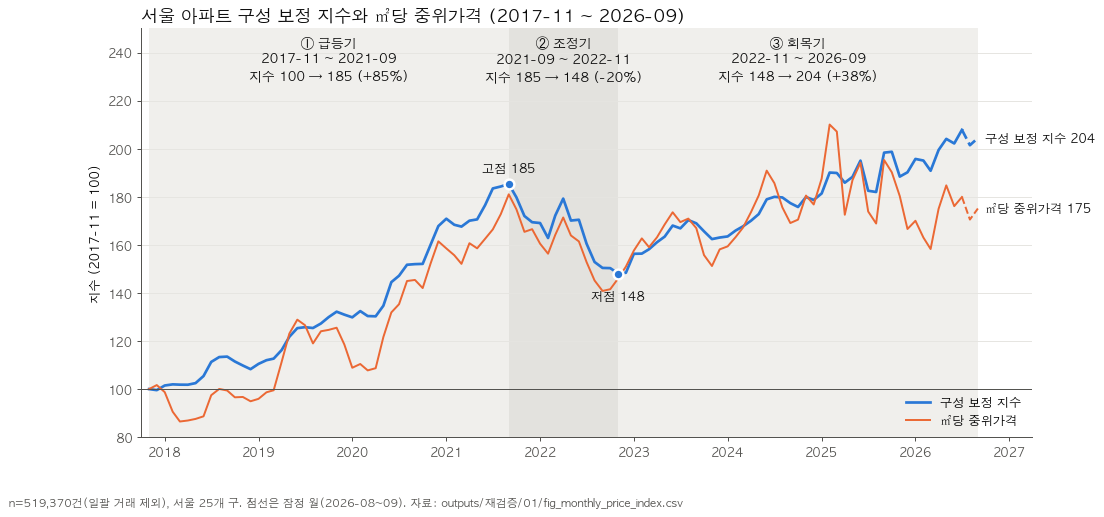

In [19]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import font_manager

_fonts = {f.name for f in font_manager.fontManager.ttflist}
for _name in ["AppleGothic", "NanumGothic", "Malgun Gothic"]:
    if _name in _fonts:
        plt.rcParams["font.family"] = _name
        break
plt.rcParams["axes.unicode_minus"] = False
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]   # 범주 색 고정 순서
INK, INK2, GRID, BAND = "#0b0b0b", "#52514e", "#e6e5e1", "#f0efec"


def style(ax, grid="y"):
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(INK2)
    ax.tick_params(colors=INK2)
    if grid:
        ax.grid(axis=grid, color=GRID, lw=0.8)
    ax.set_axisbelow(True)


def save(fig, name):
    """폭 1200px 이하 PNG로 저장하고 노트북에 표시한다(이 노트북은 Agg 백엔드라 plt.show()로는 보이지 않음)."""
    from IPython.display import Image, display
    w = fig.get_size_inches()[0]
    fig.savefig(OUT / name, dpi=min(110, 1150 / w), bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(OUT / name)))

OUT = ROOT / "outputs" / "재검증" / "01"
d = pd.read_csv(OUT / "fig_monthly_price_index.csv")
d["date"] = pd.to_datetime(d["month"])
n_nob = int(pd.read_csv(OUT / "summary.csv").set_index("key").loc["n_base_nobulk", "value"])

phases = [("① 급등기", "2017-11", "2021-09"), ("② 조정기", "2021-09", "2022-11"), ("③ 회복기", "2022-11", "2026-09")]
idx = d.set_index("month")["index_nobulk"]

fig, ax = plt.subplots(figsize=(13, 6))
for i, (lab, s, e) in enumerate(phases):
    ax.axvspan(pd.Timestamp(s), pd.Timestamp(e), color=BAND if i != 1 else "#e3e2de", zorder=0, lw=0)
    v0, v1 = idx[s], idx[e]
    mid = pd.Timestamp(s) + (pd.Timestamp(e) - pd.Timestamp(s)) / 2
    ax.text(mid, 247, f"{lab}\n{s} ~ {e}\n지수 {v0:.0f} → {v1:.0f} ({(v1 / v0 - 1) * 100:+.0f}%)",
            ha="center", va="top", fontsize=10.5, color=INK, linespacing=1.4)

fin = d[~d["is_provisional"]]
prov = d[d["month"] >= fin["month"].iloc[-1]]
for col, color, lab, lw in [("index_nobulk", SERIES[0], "구성 보정 지수", 2.2),
                            ("median_ppa_nobulk_rel", SERIES[1], "㎡당 중위가격", 1.6)]:
    ax.plot(fin["date"], fin[col], color=color, lw=lw, label=lab)
    ax.plot(prov["date"], prov[col], color=color, lw=lw, ls="--")
    ax.annotate(f"{lab} {d[col].iloc[-1]:.0f}", (d["date"].iloc[-1], d[col].iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=10, color=INK)

for m, txt, dy in [("2021-09", "고점 185", 10), ("2022-11", "저점 148", -22)]:
    ax.plot(pd.Timestamp(m), idx[m], "o", ms=8, color=SERIES[0], mec="white", mew=2, zorder=5)
    ax.annotate(txt, (pd.Timestamp(m), idx[m]), xytext=(0, dy), textcoords="offset points",
                ha="center", fontsize=10, color=INK)

ax.axhline(100, color=INK2, lw=0.8)
ax.set_ylim(80, 250)
ax.set_xlim(pd.Timestamp("2017-10"), pd.Timestamp("2027-04"))
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_ylabel("지수 (2017-11 = 100)")
ax.set_title("서울 아파트 구성 보정 지수와 ㎡당 중위가격 (2017-11 ~ 2026-09)", loc="left", fontsize=14, color=INK)
ax.legend(loc="lower right", frameon=False)
style(ax)
fig.text(0.01, -0.02, f"n={n_nob:,}건(일괄 거래 제외), 서울 25개 구. 점선은 잠정 월(2026-08~09). "
         "자료: outputs/재검증/01/fig_monthly_price_index.csv", fontsize=9, color=INK2)
save(fig, "viz_01_price_phases.png")
